# Phase 5 — Simulating the pair: joint block bootstrap

Pre-registered in `EXPERIMENTS.md` (2026-10-10 15:18 CEST) before computing. No new attempt on real data (11 IS backtests, 1 OOS access, unchanged); simulation runs: 1 (500 paths).

**Why a bootstrap and not an OU process:** an OU process assumes the mean reversion that Phases 2–3 rejected (IS Engle–Granger p = 0.975, half-life ≈ 27 years).

**Design:** daily log returns of INTC and AMD 1980–2026; moving-block bootstrap with blocks of 20 days, the **same dates for both stocks** (daily correlation preserved); 500 paths, seed 2026, real length; prices rebuilt from the real 1980 prices. On each path, exactly Phase 2: β by OLS on the simulated IS (first 8,273 days, the real split position), Engle–Granger on the simulated IS, main configuration (e = 2.0, L = 60, `shift(1)`, 5 bp/leg) on the simulated IS and on the simulated OOS with β frozen.

**How to read it:** the paths are "two correlated stocks **without** a stable relationship" — daily correlation and each stock's drift are kept, but any link beyond 20 days is destroyed. If the real Sharpe sits inside this distribution, the real pair behaves like a pair with no relationship; in the lower tail, it did worse than that (e.g. persistent trends in the real spread).

In [1]:
import logging
from datetime import date

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots

from pairs.backtest import run_strategy
from pairs.config import PROCESSED_DIR, SPLIT_DATE, TICKER_A, TICKER_B
from pairs.data import load_pair
from pairs.metrics import performance_summary
from pairs.plotting import DERIVED_COLOR, apply_style, save_figure
from pairs.simulation import BootstrapParams, bootstrap_indices, bootstrap_path, load_or_simulate
from pairs.spread import fit_hedge_ratio, stationarity_tests

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("kaleido", "choreographer", "pairs.backtest"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

FULL_END = date(2026, 10, 10)  # exclusive: last available date is 2026-10-09
params = BootstrapParams()  # pre-registered: block 20, 500 paths, seed 2026, split 8273
prices = load_pair(end=FULL_END)
assert int((prices.index < pd.Timestamp(SPLIT_DATE)).sum()) == params.split_index

# Loads data/processed/simulation_paths.pkl (written by scripts/run_simulation.py);
# recomputes only if the stored parameters or data fingerprint differ.
sims = load_or_simulate(prices, params, PROCESSED_DIR / "simulation_paths.pkl")
assert len(sims) == params.n_paths and not sims.isna().to_numpy().any()

INFO pairs.data: Loaded INTC/AMD: 11737 common days, 1980-03-17 -> 2026-10-09 (end=2026-10-10, exclusive)


INFO pairs.simulation: Loaded simulation table from C:\Users\cloti\Documents\Projects\challenge_BSQ\data\processed\simulation_paths.pkl


## Real reference values (same code as Phase 2 and OOS access #1)

Recomputed with the same functions and parameters, to compare unrounded values; identical to the logged ones (asserted).

In [2]:
fit = fit_hedge_ratio(prices, end=SPLIT_DATE)
real_eg = stationarity_tests(prices, beta=fit.beta, end=SPLIT_DATE).eg_pvalue
real_is = run_strategy(
    prices,
    fit.beta,
    entry=params.entry,
    lookback=params.lookback,
    end=SPLIT_DATE,
    trade_from=prices.index[params.is_warmup - 1].date(),
    lag=params.lag,
    cost_bps=params.cost_bps,
)
real_oos = run_strategy(
    prices,
    fit.beta,
    entry=params.entry,
    lookback=params.lookback,
    end=FULL_END,
    trade_from=SPLIT_DATE,
    lag=params.lag,
    cost_bps=params.cost_bps,
)
real_sharpe = {
    "is": performance_summary(real_is.daily, real_is.trades)["sharpe_net"],
    "oos": performance_summary(real_oos.daily, real_oos.trades)["sharpe_net"],
}
assert round(real_sharpe["is"], 2) == -0.27 and round(real_sharpe["oos"], 2) == -0.18
assert round(real_eg, 3) == 0.975
real_sharpe, real_eg

INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=-1.2311 beta=1.0471 R2=0.1499


({'is': -0.271822528078213, 'oos': -0.18056997539309189}, 0.9751934895354005)

## Summary table

`percentile of real` = share of simulated paths with a value ≤ the real one (in %).

In [3]:
def describe(sim: pd.Series, real: float) -> dict[str, float]:
    return {
        "sim median": sim.median(),
        "sim 5th pct": sim.quantile(0.05),
        "sim 95th pct": sim.quantile(0.95),
        "share of paths > 0 (%)": 100 * (sim > 0).mean(),
        "real value": real,
        "percentile of real (%)": 100 * (sim <= real).mean(),
    }


summary = pd.DataFrame(
    {
        "Sharpe net, simulated IS": describe(sims["is_sharpe_net"], real_sharpe["is"]),
        "Sharpe net, simulated OOS": describe(sims["oos_sharpe_net"], real_sharpe["oos"]),
        "Engle–Granger p, simulated IS": describe(sims["eg_pvalue"], real_eg),
    }
)
summary.loc["share of paths with p < 0.05 (%)"] = [
    np.nan,
    np.nan,
    100 * (sims["eg_pvalue"] < 0.05).mean(),
]
summary.round(3)

,"Sharpe net, simulated IS","Sharpe net, simulated OOS","Engle–Granger p, simulated IS"
sim median,0.058,0.036,0.534
sim 5th pct,-0.217,-0.388,0.046
sim 95th pct,0.321,0.461,0.975
share of paths > 0 (%),63.600,54.400,100.000
real value,-0.272,-0.181,0.975
percentile of real (%),2.800,21.000,94.800
share of paths with p < 0.05 (%),NaN,NaN,5.200


## Distribution of the net Sharpe on the simulated paths, with the real value

INFO pairs.plotting: Saved figure 05a_sharpe_bootstrap_vs_real (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


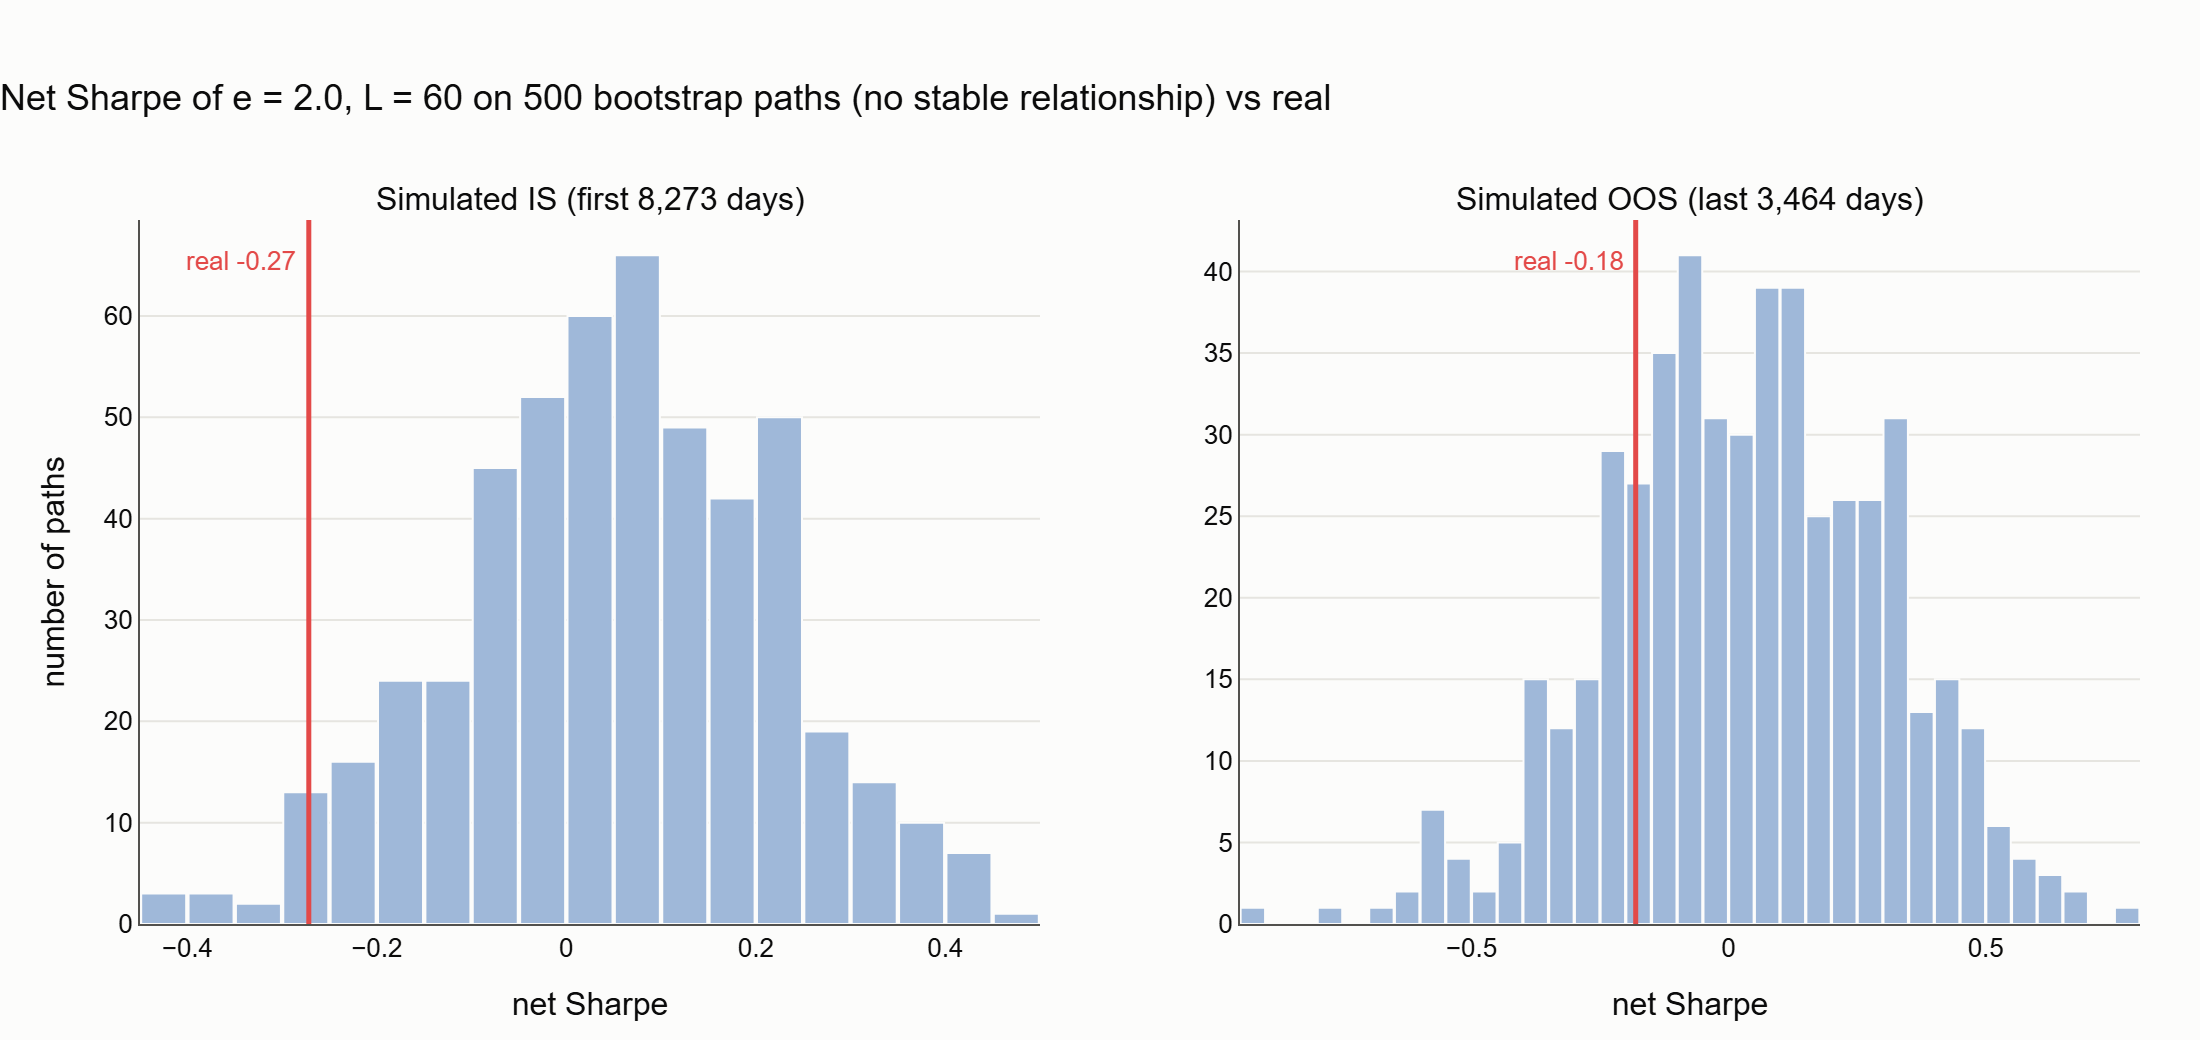

In [4]:
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Simulated IS (first 8,273 days)", "Simulated OOS (last 3,464 days)"),
    horizontal_spacing=0.10,
)
for col, key in enumerate(["is", "oos"], start=1):
    fig.add_trace(
        go.Histogram(
            x=sims[f"{key}_sharpe_net"],
            nbinsx=40,
            marker={"color": "#9fb8d9", "line": {"color": "#fcfcfb", "width": 1}},
            name="simulated paths",
            showlegend=col == 1,
        ),
        row=1,
        col=col,
    )
    fig.add_vline(
        x=real_sharpe[key],
        line={"color": "#e34948", "width": 2.5},
        row=1,
        col=col,
    )
    fig.add_annotation(
        x=real_sharpe[key],
        y=0.97,
        xref=f"x{'' if col == 1 else col}",
        yref=f"y{'' if col == 1 else col} domain",
        text=f"real {real_sharpe[key]:.2f}",
        showarrow=False,
        xanchor="right",
        yanchor="top",
        xshift=-4,
        font={"color": "#e34948", "size": 13},
    )
    fig.update_xaxes(title_text="net Sharpe", row=1, col=col)
fig.update_yaxes(title_text="number of paths", row=1, col=1)
apply_style(
    fig, "Net Sharpe of e = 2.0, L = 60 on 500 bootstrap paths (no stable relationship) vs real"
)
fig.update_layout(bargap=0.05, hovermode="closest", margin={"t": 110}, showlegend=False)
_, png = save_figure(fig, "05a_sharpe_bootstrap_vs_real", height=520)
display(Image(filename=png))

## Distribution of the Engle–Granger p-value on the simulated IS, with the real value

INFO pairs.plotting: Saved figure 05b_eg_pvalue_bootstrap_vs_real (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


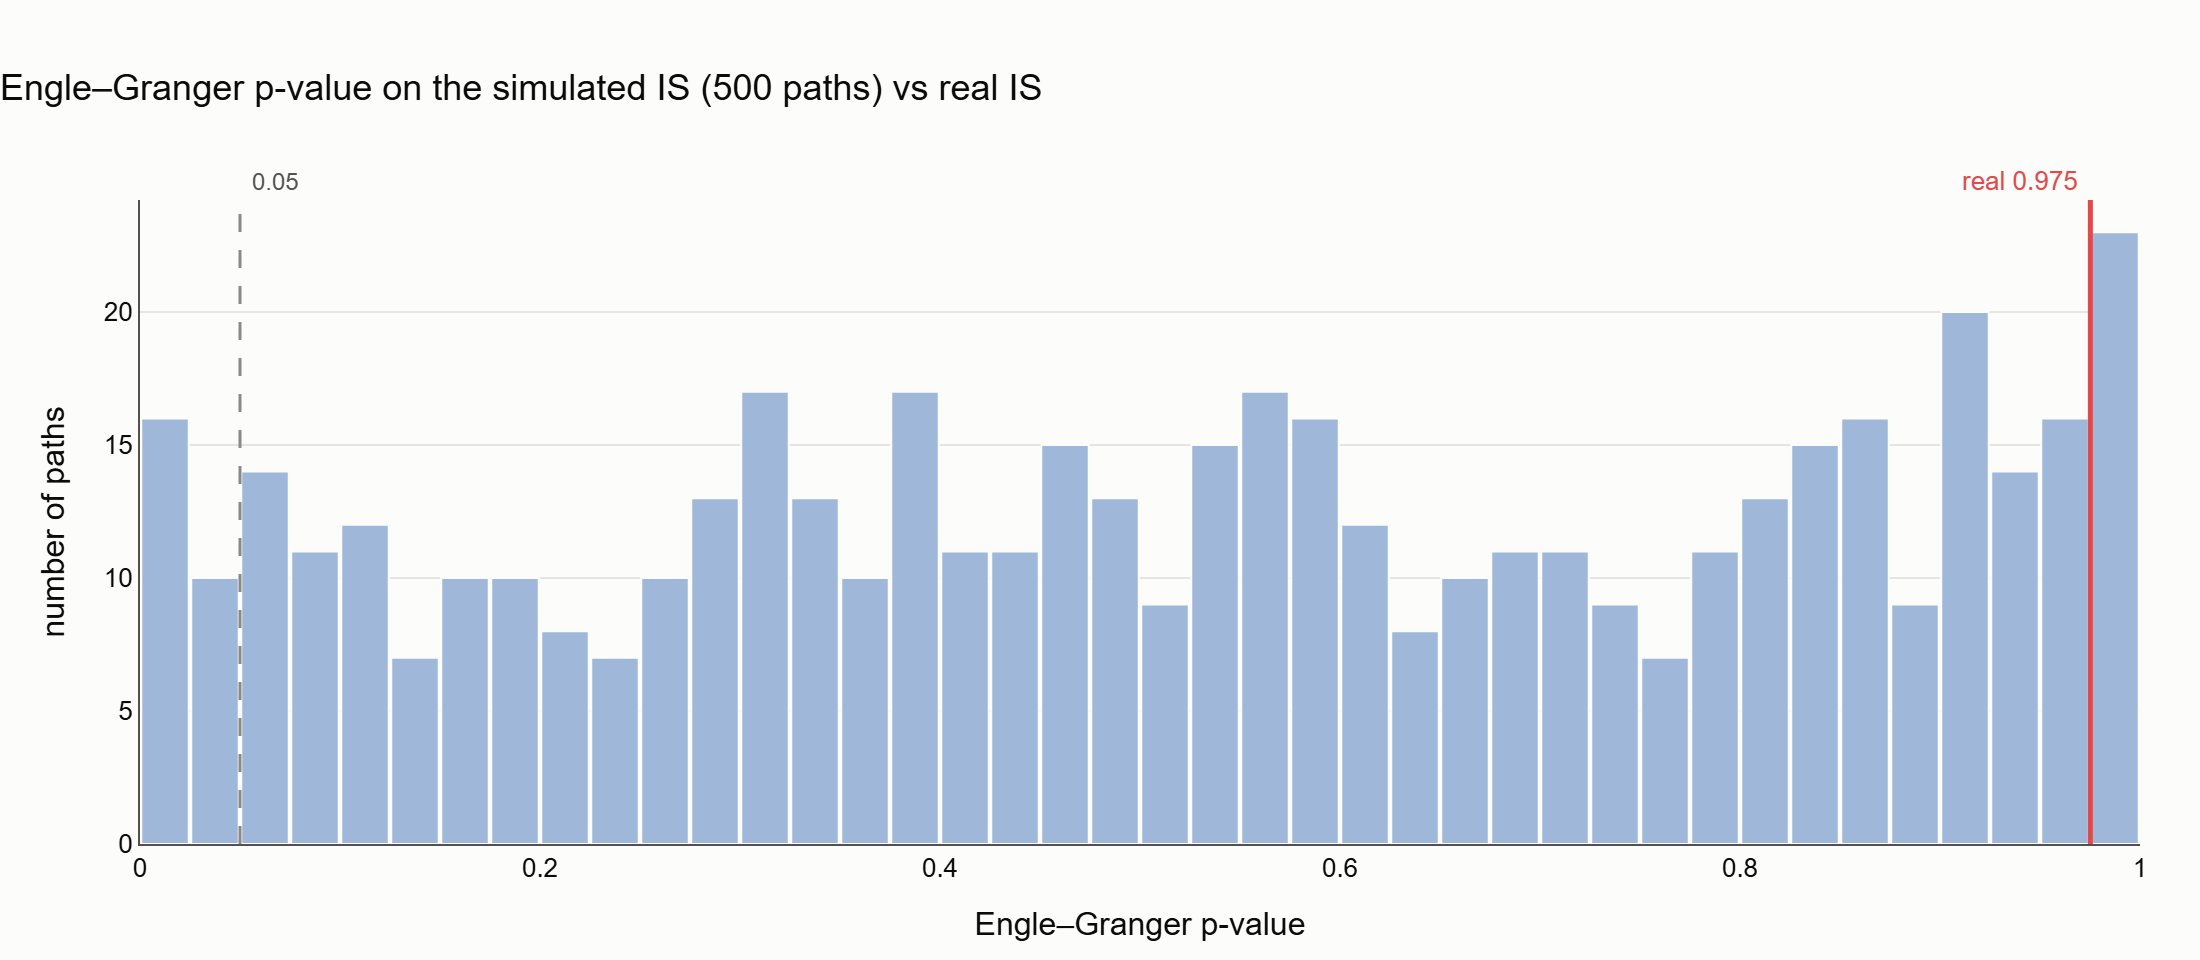

In [5]:
fig = go.Figure()
fig.add_trace(
    go.Histogram(
        x=sims["eg_pvalue"],
        xbins={"start": 0, "end": 1, "size": 0.025},
        marker={"color": "#9fb8d9", "line": {"color": "#fcfcfb", "width": 1}},
        name="simulated paths",
    )
)
fig.add_vline(x=0.05, line={"color": "#8a8984", "width": 1.5, "dash": "dash"})
fig.add_vline(x=real_eg, line={"color": "#e34948", "width": 2.5})
fig.add_annotation(
    x=real_eg,
    y=1.0,
    yref="paper",
    text=f"real {real_eg:.3f}",
    showarrow=False,
    xanchor="right",
    yanchor="bottom",
    xshift=-4,
    font={"color": "#e34948", "size": 13},
)
fig.add_annotation(
    x=0.05,
    y=1.0,
    yref="paper",
    text="0.05",
    showarrow=False,
    xanchor="left",
    yanchor="bottom",
    xshift=4,
    font={"color": "#52514e", "size": 12},
)
apply_style(fig, "Engle–Granger p-value on the simulated IS (500 paths) vs real IS")
fig.update_layout(showlegend=False, bargap=0.05, hovermode="closest", margin={"t": 100})
fig.update_xaxes(title_text="Engle–Granger p-value", range=[0, 1])
fig.update_yaxes(title_text="number of paths")
_, png = save_figure(fig, "05b_eg_pvalue_bootstrap_vs_real", height=480)
display(Image(filename=png))

## Example paths of the INTC/AMD ratio (first 5 simulated paths) vs the real ratio

The first 5 paths are regenerated with the same seed and draws as the simulation (identical to paths 0–4 of the table).

INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=-2.4319 beta=0.8586 R2=0.9126


INFO pairs.plotting: Saved figure 05c_ratio_paths_bootstrap_vs_real (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


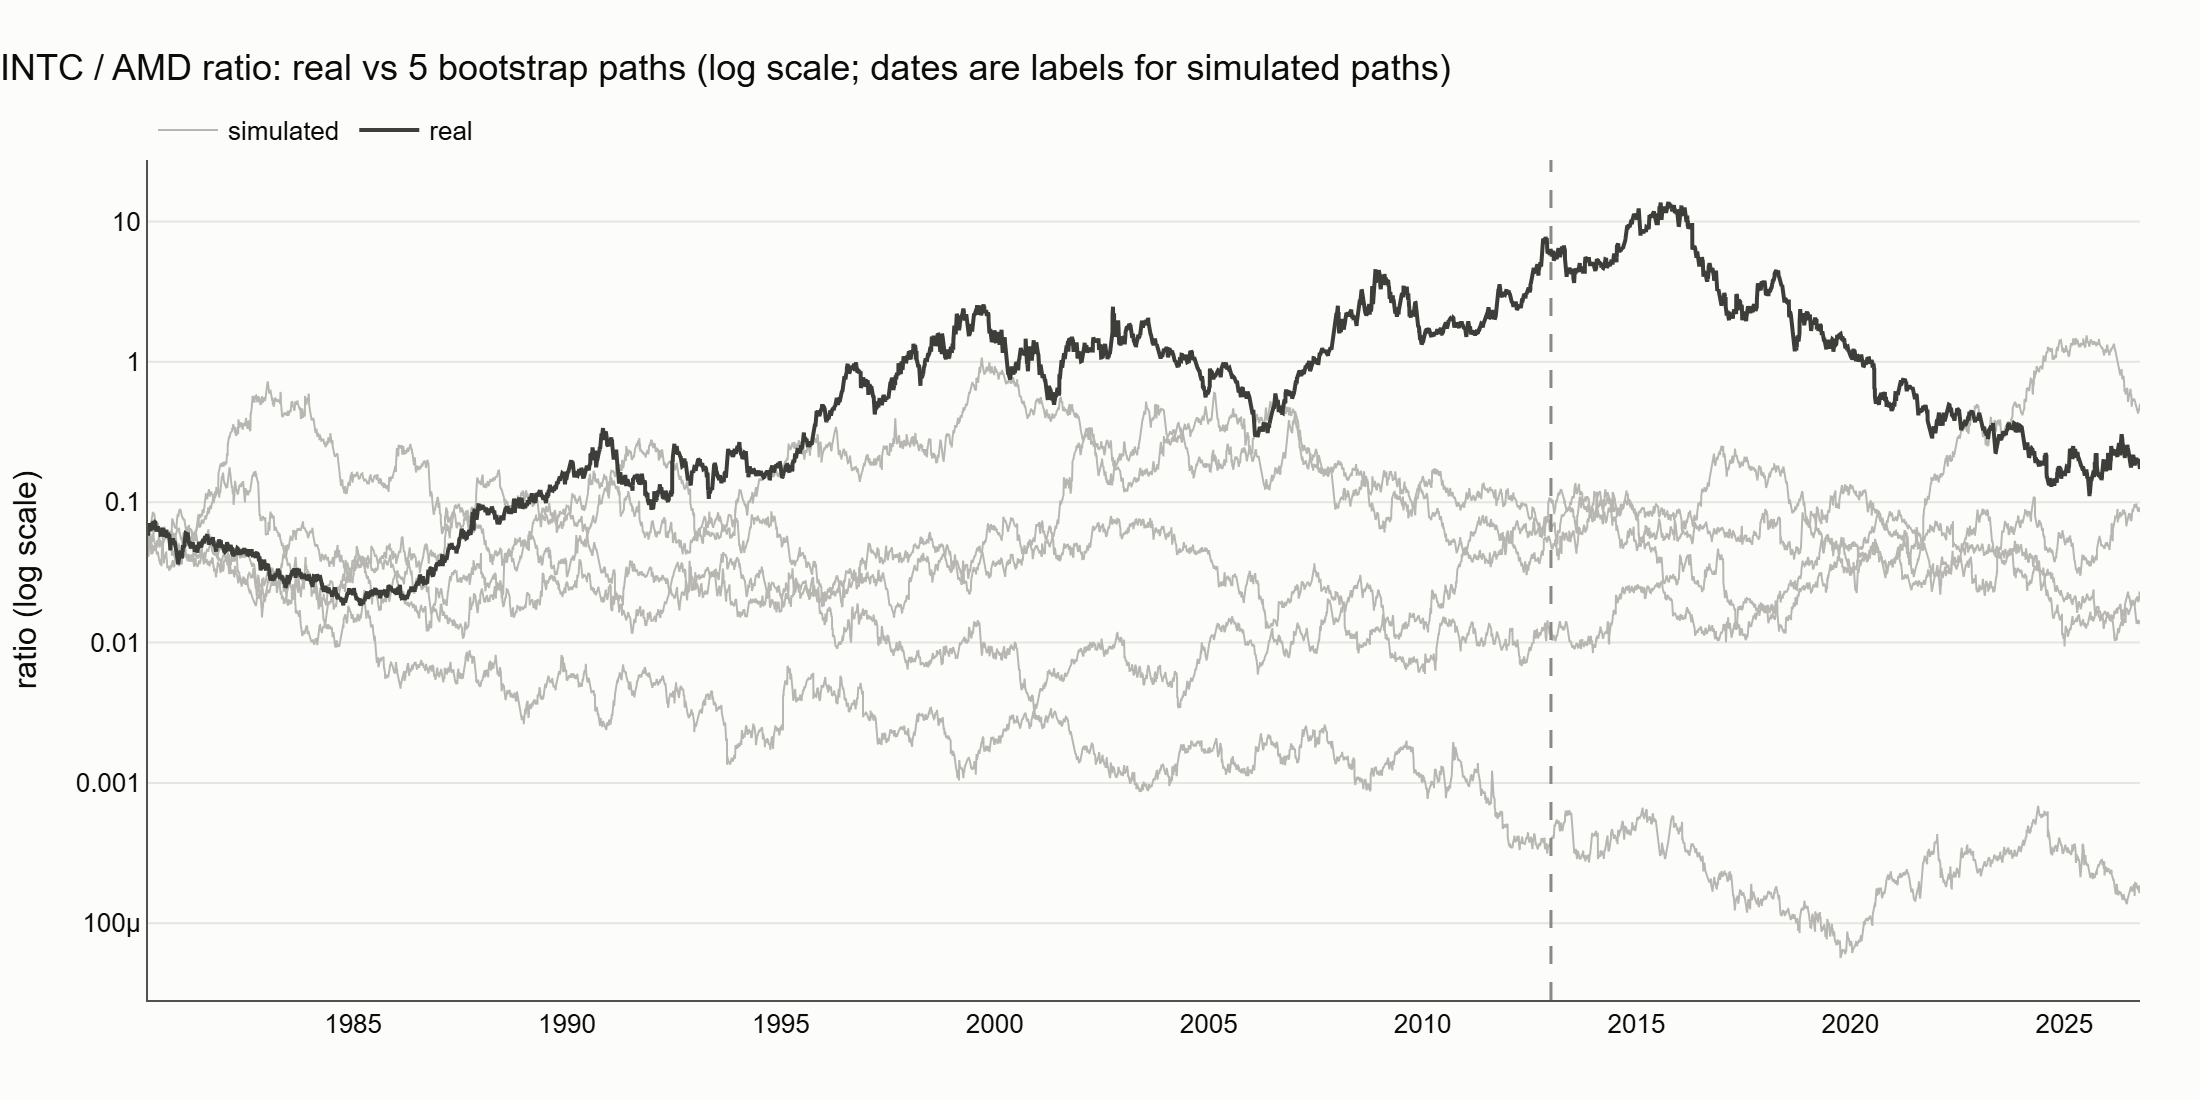

In [6]:
rng = np.random.default_rng(params.seed)
fig = go.Figure()
for k in range(5):
    path = bootstrap_path(prices, bootstrap_indices(len(prices) - 1, params.block, rng))
    ratio_k = path[TICKER_A] / path[TICKER_B]
    fig.add_trace(
        go.Scatter(
            x=ratio_k.index,
            y=ratio_k,
            name="simulated" if k == 0 else f"simulated {k}",
            line={"color": "#b7b6b0", "width": 1},
            showlegend=k == 0,
        )
    )
    if k == 0:
        assert round(
            fit_hedge_ratio(path, end=path.index[params.split_index].date()).beta, 10
        ) == round(sims.loc[0, "beta"], 10), "regenerated path 0 must match the simulation table"
real_ratio = prices[TICKER_A] / prices[TICKER_B]
fig.add_trace(
    go.Scatter(
        x=real_ratio.index, y=real_ratio, name="real", line={"color": DERIVED_COLOR, "width": 2}
    )
)
fig.add_vline(x=pd.Timestamp(SPLIT_DATE), line={"color": "#8a8984", "width": 1.5, "dash": "dash"})
apply_style(
    fig,
    "INTC / AMD ratio: real vs 5 bootstrap paths (log scale; dates are labels for simulated paths)",
)
fig.update_yaxes(
    type="log", title_text="ratio (log scale)", tickvals=[0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
)
_, png = save_figure(fig, "05c_ratio_paths_bootstrap_vs_real")
display(Image(filename=png))

## Additional descriptive numbers from the same 500 paths

In [7]:
extra = pd.Series(
    {
        "share of paths with simulated-IS beta <= 0.1 (%)": round(
            100 * (sims["beta"] <= 0.1).mean(), 1
        ),
        "share of paths with simulated-IS beta <= 0 (%)": round(
            100 * (sims["beta"] <= 0).mean(), 1
        ),
        "median simulated-IS beta": round(sims["beta"].median(), 3),
        "corr(simulated IS Sharpe, simulated OOS Sharpe)": round(
            sims["is_sharpe_net"].corr(sims["oos_sharpe_net"]), 3
        ),
        "median trades, simulated IS / OOS": (
            f"{sims['is_n_trades'].median():.0f} / {sims['oos_n_trades'].median():.0f}"
        ),
    },
    dtype=object,
)
extra.to_frame("value")

,value
share of paths with simulated-IS beta <= 0.1 (%),11.0
share of paths with simulated-IS beta <= 0 (%),9.4
median simulated-IS beta,0.683
"corr(simulated IS Sharpe, simulated OOS Sharpe)",0.031
"median trades, simulated IS / OOS",128 / 55


## Observations

- **What a "no stable relationship" world looks like for this strategy:** on the simulated IS the net Sharpe has median 0.06 (5th–95th percentile −0.22 to 0.32) and is positive on 64% of paths; on the simulated OOS, median 0.04 (−0.39 to 0.46), positive on 54%. Without any long-run link, the strategy is roughly a coin flip around a slightly positive Sharpe — and the simulated IS Sharpe says nothing about the simulated OOS Sharpe (correlation 0.03).
- **Real IS (Phase 2): −0.27, at the 2.8th percentile.** The real pair did *worse* than 97% of the correlated-but-unrelated worlds. Consistent with pre-registered reading 4 and with Phase 3: the real static-β spread had persistent multi-year trends (it behaves largely like a short AMD position), longer than the 20-day blocks preserve, and a mean-reversion strategy without stop-loss loses on persistent trends. This percentile is descriptive, not a pre-registered hypothesis test.
- **Real OOS (access #1): −0.18, at the 21st percentile** — inside the bulk of the no-relationship distribution: out-of-sample, the pair is indistinguishable from two correlated stocks with no stable relationship.
- **Engle–Granger p under the null** is roughly uniform: 5.2% of paths have p < 0.05, close to the nominal 5% (the test behaves as it should). The real IS p = 0.975 sits at the 94.8th percentile — even less evidence of cointegration than a typical unrelated pair.
- **β under the null:** median 0.68, ≤ 0.1 on 11% of paths (≤ 0 on 9.4%) — a single static β estimated on a no-relationship pair can land anywhere, as the rolling β of Phase 3 did on the real data.
- **Conclusion:** the simulation supports the Phase 2–3 diagnosis. Nothing in the real results requires a stable INTC/AMD relationship to explain it; the IS loss is, if anything, larger than chance alone would produce in such a world, because of persistent trends in the real spread.

## Look-elsewhere effect

Pre-registered in `EXPERIMENTS.md` (2026-10-10 18:37 CEST) before computing. A simulation, not a strategy attempt (INTC/AMD counters unchanged: 14 IS backtests, 2 OOS accesses; simulation runs 1 → 2).

**Disclosure:** the window **1997-01-01 → 2004-12-31 was chosen a posteriori**, by looking at the INTC/AMD price charts (the user's idea: in that period the two stocks *looked* linked). The question is how easily such a window appears **by chance** when one searches a long history for it.

- **Real window:** β by OLS on the window's own log prices (deliberate in-window look-ahead — what someone fooled by the window would do), Engle–Granger on the window, net Sharpe of the main configuration (e = 2.0, L = 60, `shift(1)`, 5 bp/leg) with prices restricted to the window, evaluated from the window's first L = 120 z-score day.
- **Null world:** the same Phase 5 bootstrap paths (seed 2026, block 20), regenerated and checked against the Phase 5 table; on each path, windows of the same length starting every 252 days, with the same procedure. The runtime estimate for 500 paths was ≈ 45 min > 20 min, so **the first 200 paths are used**, as pre-registered.

In [8]:
import pickle
from dataclasses import asdict

from pairs.simulation import evaluate_window, look_elsewhere_summary
from pairs.spread import compute_spread

WINDOW_START, WINDOW_END = pd.Timestamp("1997-01-01"), pd.Timestamp("2004-12-31")
window = prices[(prices.index >= WINDOW_START) & (prices.index <= WINDOW_END)]
real_w = evaluate_window(window, params)
print(
    f"Real window {window.index[0].date()} -> {window.index[-1].date()}: "
    f"{len(window)} trading days; "
    f"in-window β = {real_w['beta']:.4f}, Engle–Granger p = {real_w['eg_pvalue']:.4f}, "
    f"net Sharpe = {real_w['sharpe_net']:.3f}"
)

INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1997-01-02..2004-12-31: alpha=1.4866 beta=0.4799 R2=0.4059


Real window 1997-01-02 -> 2004-12-31: 2013 trading days; in-window β = 0.4799, Engle–Granger p = 0.5118, net Sharpe = 0.222


INFO pairs.plotting: Saved figure 05d_lookelsewhere_spread_1997_2004 (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


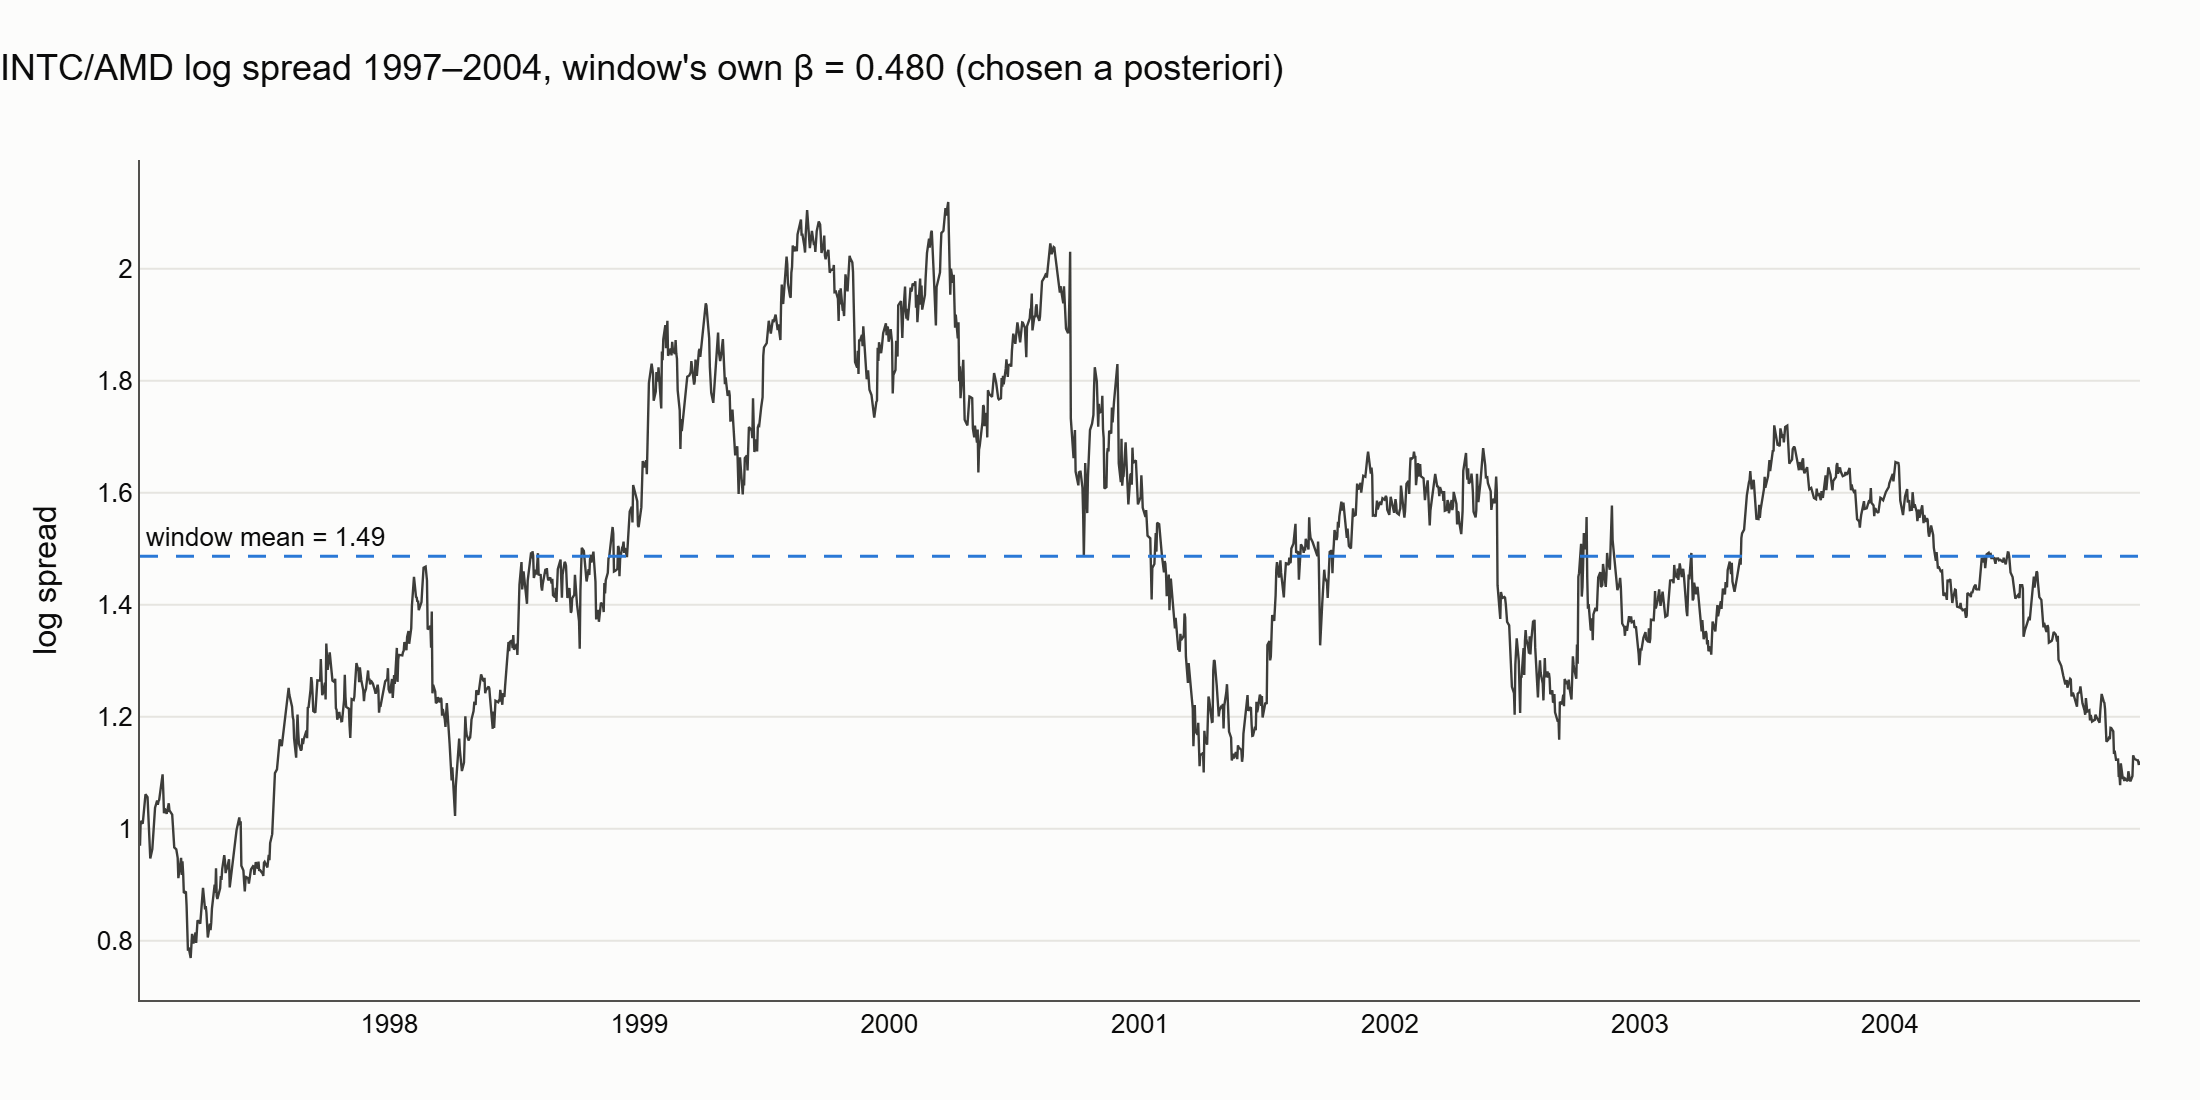

In [9]:
spread_w = compute_spread(window, real_w["beta"])
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=spread_w.index, y=spread_w, name="spread", line={"color": DERIVED_COLOR, "width": 1.2}
    )
)
fig.add_hline(
    y=spread_w.mean(),
    line={"color": "#2a78d6", "width": 1.5, "dash": "dash"},
    annotation_text=f"window mean = {spread_w.mean():.2f}",
    annotation_position="top left",
)
apply_style(
    fig,
    f"INTC/AMD log spread 1997–2004, window's own β = {real_w['beta']:.3f} (chosen a posteriori)",
)
fig.update_layout(showlegend=False)
fig.update_yaxes(title_text="log spread")
_, png = save_figure(fig, "05d_lookelsewhere_spread_1997_2004")
display(Image(filename=png))

In [10]:
# Computed once by scripts/run_look_elsewhere.py; reloaded here.
with (PROCESSED_DIR / "look_elsewhere_windows.pkl").open("rb") as f:
    le = pickle.load(f)
assert le["params"] == asdict(params) and le["window_len"] == len(window)
assert le["step"] == 252 and le["n_paths"] == 200
windows_null = le["table"]
assert windows_null["path"].nunique() == 200

s = look_elsewhere_summary(
    windows_null, real_pvalue=real_w["eg_pvalue"], real_sharpe=real_w["sharpe_net"]
)
n_win = int(s["n_windows"] / s["n_paths"])
d_range = (
    f"{s['d_best_sharpe_median']:.2f} [{s['d_best_sharpe_p5']:.2f}, {s['d_best_sharpe_p95']:.2f}]"
)
rows = {
    "paths / windows per path / windows": f"{int(s['n_paths'])} / {n_win} / {int(s['n_windows'])}",
    "real window: Engle–Granger p": f"{real_w['eg_pvalue']:.4f}",
    "real window: net Sharpe": f"{real_w['sharpe_net']:.3f}",
    "(a) single windows with p < 0.05": f"{s['a_share_windows_p_lt_005']:.1f}%",
    "(b) paths with at least one window p < 0.05": f"{s['b_share_paths_any_p_lt_005']:.1f}%",
    "(c) paths with a window as good as the real one (p ≤ real and Sharpe ≥ real)": (
        f"{s['c_share_paths_any_as_good_as_real']:.1f}%"
    ),
    "(d) best-window Sharpe per path: median [5th, 95th pct]": d_range,
    "(d) percentile of the real Sharpe among best windows": (
        f"{s['d_real_percentile_among_best']:.1f}%"
    ),
}
pd.DataFrame({"value": rows})

,value
paths / windows per path / windows,200 / 39 / 7800
real window: Engle–Granger p,0.5118
real window: net Sharpe,0.222
(a) single windows with p < 0.05,5.8%
(b) paths with at least one window p < 0.05,78.5%
(c) paths with a window as good as the real one (p ≤ real and Sharpe ≥ real),99.5%
"(d) best-window Sharpe per path: median [5th, 95th pct]","0.80 [0.48, 1.17]"
(d) percentile of the real Sharpe among best windows,0.0%


INFO pairs.plotting: Saved figure 05e_lookelsewhere_best_window_sharpe (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


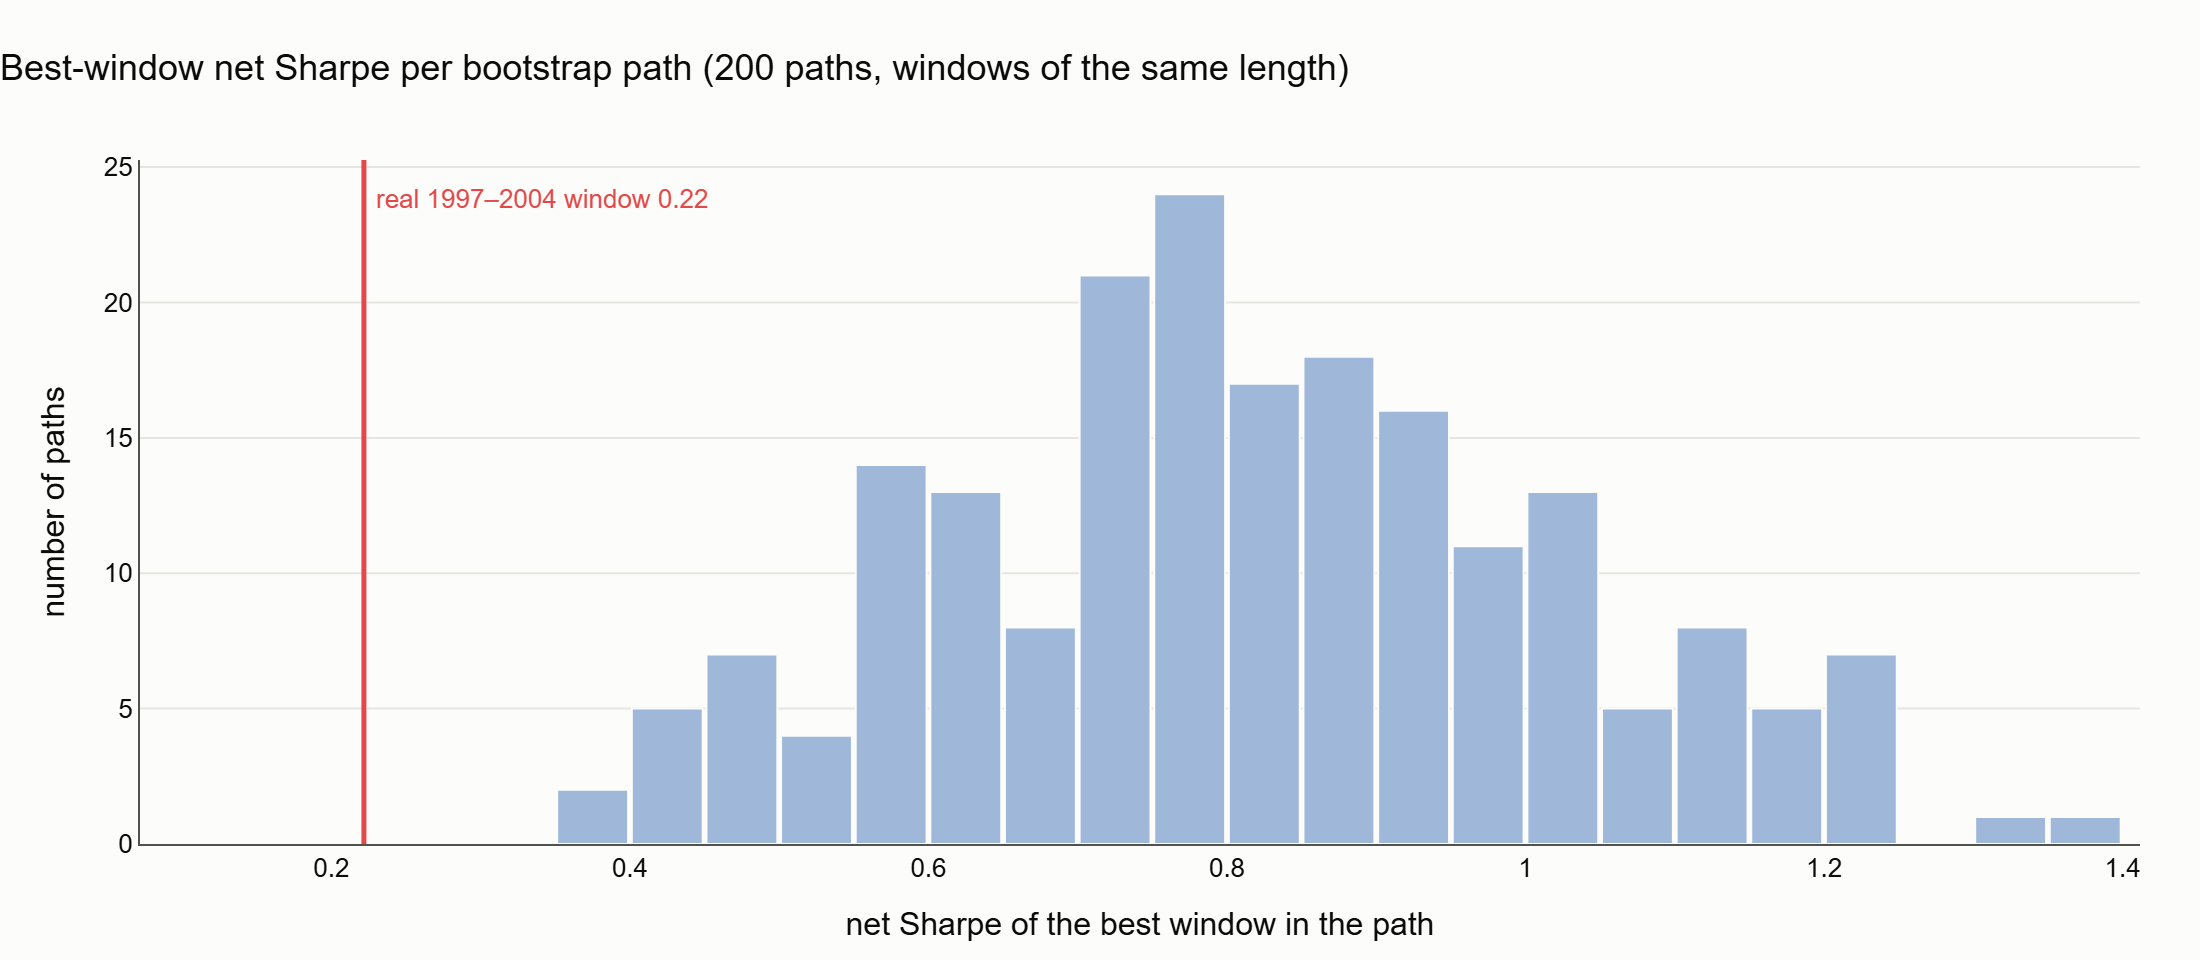

In [11]:
best = windows_null.groupby("path")["sharpe_net"].max()
fig = go.Figure()
fig.add_trace(
    go.Histogram(
        x=best, nbinsx=30, marker={"color": "#9fb8d9", "line": {"color": "#fcfcfb", "width": 1}}
    )
)
fig.add_vline(x=real_w["sharpe_net"], line={"color": "#e34948", "width": 2.5})
fig.add_annotation(
    x=real_w["sharpe_net"],
    y=0.97,
    yref="y domain",
    text=f"real 1997–2004 window {real_w['sharpe_net']:.2f}",
    showarrow=False,
    xanchor="left",
    yanchor="top",
    xshift=4,
    font={"color": "#e34948", "size": 13},
)
apply_style(
    fig, "Best-window net Sharpe per bootstrap path (200 paths, windows of the same length)"
)
fig.update_layout(showlegend=False, bargap=0.05, hovermode="closest")
fig.update_xaxes(
    title_text="net Sharpe of the best window in the path",
    range=[min(real_w["sharpe_net"], best.min()) - 0.15, best.max() + 0.05],
)
fig.update_yaxes(title_text="number of paths")
_, png = save_figure(fig, "05e_lookelsewhere_best_window_sharpe", height=480)
display(Image(filename=png))

### Observations on the look-elsewhere analysis

- **The a-posteriori window is not even cointegrated:** 1997–2004 (2,013 trading days), in-window β = 0.48, Engle–Granger p = 0.51; with that in-window β (look-ahead), the main configuration earns a net Sharpe of 0.22. The visual impression that the two stocks "looked linked" there does not survive the test.
- **(a) Single windows:** 5.8% of the 7,800 null windows have p < 0.05 — close to the nominal 5%, as it should be for a test applied once.
- **(b) Searching changes everything:** 78.5% of the null paths contain **at least one** window with p < 0.05. In a world with no stable relationship, someone scanning ~39 windows of a history like this one would "find cointegration" in about four histories out of five.
- **(c)** 99.5% of null paths contain a window at least as good as the real one (p ≤ 0.51 and Sharpe ≥ 0.22): the real window is unremarkable by null standards.
- **(d) Best window per path:** median net Sharpe 0.80 (5th–95th percentile 0.48 to 1.17); the real window (0.22) is **below every** path's best window (0th percentile).
- **Reading:** a period that looks like a relationship when chosen by eye is exactly what chance produces when a long history is searched; here the chosen window is weaker than what the search would typically find in a no-relationship world. Caveats: 200 of the 500 paths (pre-registered fallback, the 500-path estimate exceeded 20 minutes); windows start every 252 days (a finer search would make (b) and (d) larger still); the null is the Phase 5 bootstrap world (daily co-movement and drifts kept, no link beyond 20 days).